samples: 50000 10000 10000
batches: 391 79 79
images: torch.Size([128, 1, 28, 28]) torch.float32
labels: torch.Size([128]) torch.int64
pixel range: 0.0 1.0
flattened: torch.Size([128, 784])


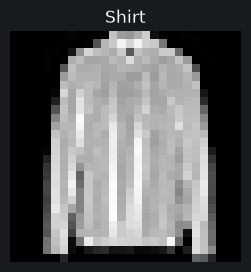

In [6]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor

DATA_ROOT = (
    "../Unit2_Datasets_and_DataLoaders/data"
)
transform = ToTensor() # TODO 1: 创建 ToTensor 转换
full_train = FashionMNIST(DATA_ROOT, train=True, transform=transform, download=False)
test_dataset = FashionMNIST(DATA_ROOT, train=False, transform=transform, download=False)

split_g = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(full_train, [50000, 10000], generator=split_g) # TODO 2: 划分为 50000 和 10000，使用 split_g
shuffle_g = torch.Generator().manual_seed(123)
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=shuffle_g) # TODO 3: 训练 DataLoader
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False) # TODO 4: 验证 DataLoader
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False) # TODO 5: 测试 DataLoader

X_batch, y_batch = next(iter(val_loader))
X_flat = X_batch.flatten(start_dim=1) # TODO 6: 保留样本轴，把图片展平
print("samples:", len(train_dataset), len(val_dataset), len(test_dataset))
print("batches:", len(train_loader), len(val_loader), len(test_loader))
print("images:", X_batch.shape, X_batch.dtype)
print("labels:", y_batch.shape, y_batch.dtype)
print("pixel range:", X_batch.min().item(), X_batch.max().item())
print("flattened:", X_flat.shape)
assert not (set(train_dataset.indices) & set(val_dataset.indices))
assert X_batch.dtype == torch.float32
assert y_batch.dtype == torch.long

plt.figure(figsize=(3, 3))
plt.imshow(X_batch[0, 0].numpy(), cmap="gray", vmin=0, vmax=1)
plt.title(full_train.classes[y_batch[0].item()])
plt.axis("off")
plt.show()

# 手写分类前向

In [7]:
import torch

torch.manual_seed(42)

# TODO 1：创建权重
W = (torch.randn(784, 10) * 0.01).requires_grad_()

# TODO 2：创建偏置
b = torch.zeros(10, requires_grad=True)


def manual_logits(X):
    # TODO 3：保留 batch 轴，把每张图片展平
    X_flat = X.flatten(start_dim=1)

    # TODO 4：计算并返回原始类别分数
    return X_flat @ W + b


X_batch, y_batch = next(iter(val_loader))
logits = manual_logits(X_batch)

# TODO 5：从每行分数中选出预测类别编号
predicted_classes = logits.argmax(dim=1)

print("logits 形状：", logits.shape)
print("预测编号形状：", predicted_classes.shape)
print("参数数量：", W.numel() + b.numel())
print("logits 是否需要梯度：", logits.requires_grad)

assert W.shape == (784, 10)
assert b.shape == (10,)
assert W.requires_grad and b.requires_grad
assert W.is_leaf and b.is_leaf
assert logits.shape == (X_batch.shape[0], 10)
assert predicted_classes.shape == y_batch.shape
assert logits.requires_grad

logits 形状： torch.Size([128, 10])
预测编号形状： torch.Size([128])
参数数量： 7850
logits 是否需要梯度： True


# 损失与指标小实验

In [8]:
import torch
from torch import nn

toy_logits = torch.tensor([
    [2.0, 0.0, 0.0],
    [0.0, 2.0, 0.0],
    [0.0, 0.0, 2.0],
    [0.0, 2.0, 0.0],
    [0.0, 0.0, 2.0],
])
toy_labels = torch.tensor([0, 1, 2, 0, 0], dtype=torch.long)

batches = [
    (toy_logits[:4], toy_labels[:4]),
    (toy_logits[4:], toy_labels[4:]),
]
loss_fn = nn.CrossEntropyLoss()
loss_sum = 0.0
correct_sum = 0
sample_count = 0

for batch_logits, batch_labels in batches:
    n = batch_labels.numel()

    batch_loss = loss_fn(batch_logits, batch_labels)  # TODO 1：计算本批平均交叉熵
    predicted_classes = batch_logits.argmax(dim=1) # TODO 2：得到本批预测类别编号
    batch_correct = (predicted_classes == batch_labels).sum().item()  # TODO 3：统计正确数量，转为 Python 数值

    loss_sum += n * batch_loss.item() # TODO 4：还原本批损失总和，再累计
    correct_sum += batch_correct
    sample_count += n

mean_loss = loss_sum / sample_count # TODO 5：整体平均损失
accuracy = correct_sum / sample_count # TODO 6：整体准确率，先保留为 0～1 的比例

print(f"mean loss: {mean_loss:.6f}")
print(f"accuracy: {accuracy:.1%}")

# 用一次性计算的结果核对逐批汇总
reference_loss = loss_fn(toy_logits, toy_labels).item()
assert abs(mean_loss - reference_loss) < 1e-6
assert sample_count == 5
assert correct_sum == 3
assert abs(accuracy - 0.6) < 1e-6

mean loss: 1.039545
accuracy: 60.0%


# 训练与验证实验

In [9]:
import torch
from torch import nn
from torch.utils.data import DataLoader

torch.manual_seed(42)
W = (torch.randn(784, 10) * 0.01).requires_grad_()
b = torch.zeros(10, requires_grad=True)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD([W, b], lr=0.1)
train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)
train_eval_loader = DataLoader(train_dataset, batch_size=128, shuffle=False)

def evaluate_classifier(loader):
    loss_sum, correct_sum, sample_count = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            logits = manual_logits(X)
            loss = loss_fn(logits, y)
            n = y.numel()
            loss_sum += n * loss.item() # TODO 1：累计本批损失总和
            correct_sum += (logits.argmax(dim=1) == y).sum().item() # TODO 2：累计正确数量，使用 Python 数值
            sample_count += n
    return loss_sum / sample_count, correct_sum / sample_count              # TODO 3：返回整体平均 loss、accuracy

history = []
before_W, before_b = W.detach().clone(), b.detach().clone()
initial_train = evaluate_classifier(train_eval_loader)
initial_val = evaluate_classifier(val_loader)
assert torch.equal(W, before_W) and torch.equal(b, before_b)
print("Before training:", initial_train, initial_val)

for epoch in range(10):
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()                      # TODO 4：清除旧梯度
        logits = manual_logits(X_batch)             # TODO 5：调用手写前向
        loss = loss_fn(logits, y_batch)               # TODO 6：计算平均交叉熵
        loss.backward()          # TODO 7：反向传播
        optimizer.step()         # TODO 8：更新参数

    train_loss, train_acc = evaluate_classifier(train_eval_loader)
    val_loss, val_acc = evaluate_classifier(val_loader)
    history.append((train_loss, train_acc, val_loss, val_acc))
    print(
        f"epoch {epoch + 1:02d}: "
        f"train loss {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val loss {val_loss:.4f}, acc {val_acc:.1%}"
    )

assert len(history) == 10
assert not torch.equal(W, before_W) or not torch.equal(b, before_b)

Before training: (2.322948656234741, 0.10234) (2.3244849533081053, 0.1017)
epoch 01: train loss 0.5592, acc 81.7%; val loss 0.5750, acc 81.3%
epoch 02: train loss 0.5103, acc 82.6%; val loss 0.5275, acc 82.0%
epoch 03: train loss 0.4814, acc 83.6%; val loss 0.5025, acc 82.8%
epoch 04: train loss 0.4627, acc 84.3%; val loss 0.4838, acc 83.7%
epoch 05: train loss 0.4614, acc 84.2%; val loss 0.4821, acc 83.7%
epoch 06: train loss 0.4549, acc 84.3%; val loss 0.4783, acc 83.2%
epoch 07: train loss 0.4379, acc 85.1%; val loss 0.4607, acc 84.3%
epoch 08: train loss 0.4383, acc 85.2%; val loss 0.4617, acc 84.6%
epoch 09: train loss 0.4263, acc 85.5%; val loss 0.4532, acc 84.5%
epoch 10: train loss 0.4315, acc 85.3%; val loss 0.4587, acc 84.4%


In [10]:
import torch
from torch import nn
from torch.utils.data import DataLoader

loss_fn = nn.CrossEntropyLoss()
model = nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(784, 10),
)  # TODO 1：Sequential，先展平，再 Linear(784, 10)
with torch.no_grad():
    model[1].weight.copy_(before_W.T)  # TODO 2：复制手写版初始权重的转置
    model[1].bias.copy_(before_b)    # TODO 3：复制手写版初始偏置
framework_optimizer = torch.optim.SGD(model.parameters(), lr=0.1)  # TODO 4：新模型参数
framework_train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(123),
)

def evaluate_model(net, loader):
    net.eval()
    loss_sum, correct_sum, sample_count = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            logits = net(X)
            loss = loss_fn(logits, y)
            n = y.numel()
            loss_sum += n * loss.item() # TODO 1：累计本批损失总和
            correct_sum += (logits.argmax(dim=1) == y).sum().item() # TODO 2：累计正确数量，使用 Python 数值
            sample_count += n
    return loss_sum / sample_count, correct_sum / sample_count              # TODO 3：返回整体平均 loss、accuracy

X_check, _ = next(iter(val_loader))
with torch.no_grad():
    reference = X_check.flatten(start_dim=1) @ before_W + before_b
    assert torch.allclose(model(X_check), reference, atol=1e-6, rtol=1e-5)

framework_history = []
for epoch in range(10):
    model.train()
    for X_batch, y_batch in framework_train_loader:
        framework_optimizer.zero_grad()
        logits = model(X_batch) # TODO 5：用新模型计算原始类别分数
        loss = loss_fn(logits, y_batch)
        loss.backward()
        framework_optimizer.step()

    train_loss, train_acc = evaluate_model(model, train_eval_loader)
    val_loss, val_acc = evaluate_model(model, val_loader)
    framework_history.append((train_loss, train_acc, val_loss, val_acc))
    print(
        f"epoch {epoch + 1:02d}: "
        f"train loss {train_loss:.4f}, acc {train_acc:.1%}; "
        f"val loss {val_loss:.4f}, acc {val_acc:.1%}"
    )

assert len(framework_history) == 10

epoch 01: train loss 0.5592, acc 81.7%; val loss 0.5750, acc 81.3%
epoch 02: train loss 0.5103, acc 82.6%; val loss 0.5275, acc 82.0%
epoch 03: train loss 0.4814, acc 83.6%; val loss 0.5025, acc 82.8%
epoch 04: train loss 0.4627, acc 84.3%; val loss 0.4838, acc 83.7%
epoch 05: train loss 0.4614, acc 84.2%; val loss 0.4821, acc 83.7%
epoch 06: train loss 0.4549, acc 84.3%; val loss 0.4783, acc 83.2%
epoch 07: train loss 0.4379, acc 85.1%; val loss 0.4607, acc 84.3%
epoch 08: train loss 0.4383, acc 85.2%; val loss 0.4617, acc 84.6%
epoch 09: train loss 0.4263, acc 85.5%; val loss 0.4532, acc 84.5%
epoch 10: train loss 0.4315, acc 85.3%; val loss 0.4587, acc 84.4%


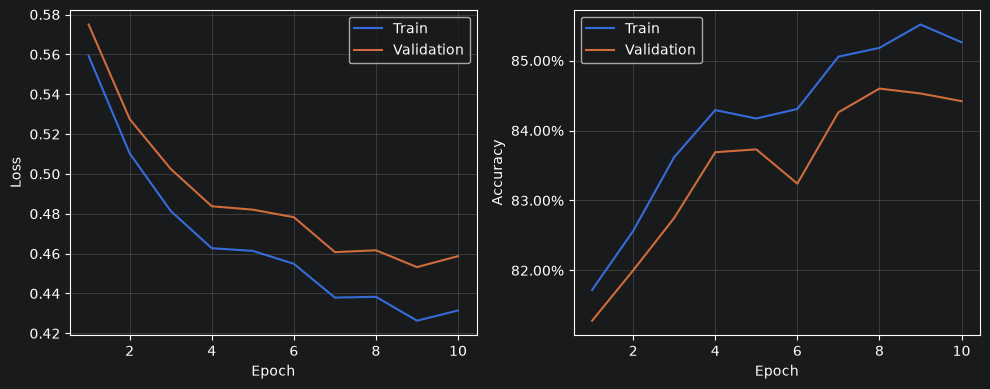

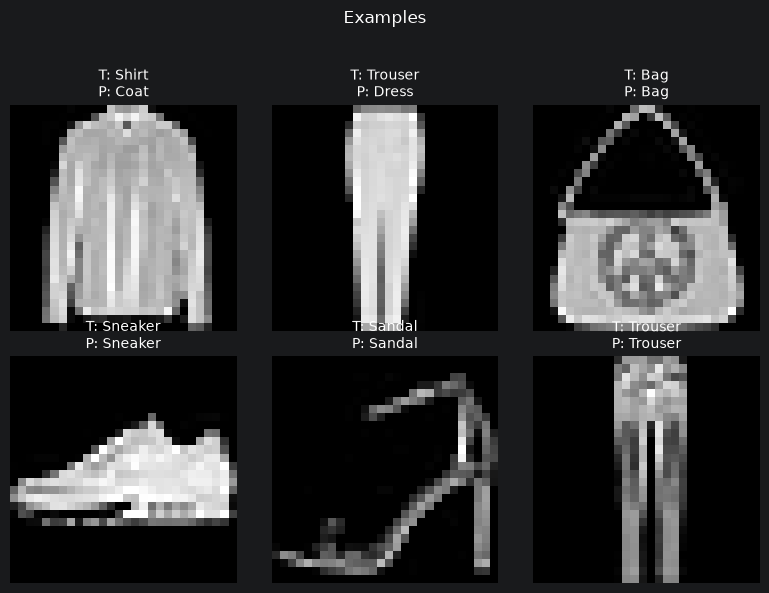

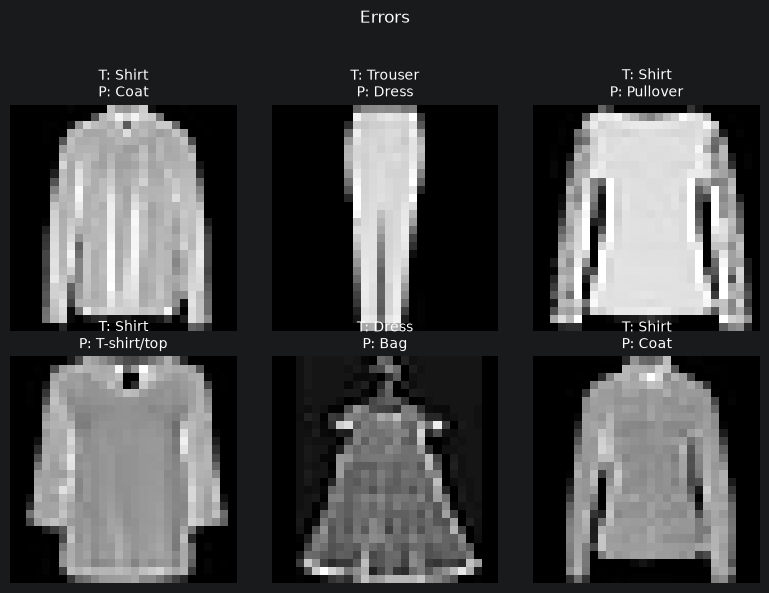

In [11]:
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

train_l, train_a, val_l, val_a = zip(*framework_history)
epochs = range(1, len(framework_history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, train_values, val_values, ylabel in zip(
    axes, (train_l, train_a), (val_l, val_a), ("Loss", "Accuracy")
):
    ax.plot(epochs, train_values, label="Train")
    ax.plot(epochs, val_values, label="Validation")
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
fig.tight_layout()
plt.show()

model.eval()
X_show, y_show = next(iter(val_loader))
with torch.no_grad():
    predictions = model(X_show).argmax(dim=1)
wrong_ids = (predictions != y_show).nonzero(as_tuple=True)[0][:6].tolist()

for heading, ids in [
    ("Examples", range(min(6, len(y_show)))), ("Errors", wrong_ids)
]:
    if len(ids) == 0:
        print("No errors in this batch.")
        continue
    fig, axes = plt.subplots(2, 3, figsize=(8, 6))
    fig.suptitle(heading)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, ids):
        true_name = full_train.classes[y_show[i].item()]
        pred_name = full_train.classes[predictions[i].item()]
        ax.imshow(X_show[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"T: {true_name}\nP: {pred_name}", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()